# Mental Pulse — Analiz v2 (yeniden üretilebilir, sızıntısız değerlendirme)

Bu not defteri, orijinal [`analiz.ipynb`](analiz.ipynb) çalışmasının **bilimsel olarak gözden geçirilmiş** sürümüdür.
Amaç; veri setini kaynağına kadar izlemek, veri kalitesini sınamak, kategorik değişkenler için doğru ilişki ölçülerini
kullanmak ve modelleri **veri sızıntısı olmadan**, **taban çizgilerine (baseline) karşı**, **istatistiksel anlamlılık (permütasyon)**,
**kalibrasyon (Brier)** ve **alt grup adaleti (fairness)** ölçütleriyle değerlendirmektir.

**Veri kaynağı:** RHMCD-20 — *The RHMCD-20 datasets for Depression and Mental Health Data Analysis with Machine Learning*
(Salehin & Amin, Mendeley Data, 2023, DOI: [10.17632/pxjmjyfdh2](https://doi.org/10.17632/pxjmjyfdh2.2), CC BY 4.0).
Veri makalesi: Amin, Salehin, Baten & Al Noman (2024), *Data in Brief* 54:110376, DOI: [10.1016/j.dib.2024.110376](https://doi.org/10.1016/j.dib.2024.110376).

**İlgili belgeler:**
- [`docs/ARASTIRMA_RAPORU.md`](../docs/ARASTIRMA_RAPORU.md)
- [`docs/LITERATUR_MATRISI.md`](../docs/LITERATUR_MATRISI.md)
- [`docs/VERI_KARTI_RHMCD20.md`](../docs/VERI_KARTI_RHMCD20.md)
- [`docs/TRIPOD_AI_KONTROL_LISTESI.md`](../docs/TRIPOD_AI_KONTROL_LISTESI.md)
- [`docs/ETIK_VE_KVKK_CERCEVESI.md`](../docs/ETIK_VE_KVKK_CERCEVESI.md)

In [1]:
import os, sys, warnings, platform
from pathlib import Path
warnings.filterwarnings("ignore")

# Paket kurulu değilse src/ yolunu ekle
SRC_PATH = Path("..").resolve() / "src"
if str(SRC_PATH) not in sys.path:
    sys.path.insert(0, str(SRC_PATH))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy
import sklearn

from mental_pulse.data import (
    TR_LABELS,
    check_documentation_consistency,
    check_plausibility,
    check_uniformity,
    load_rhmcd20,
)
from mental_pulse.stats import pairwise_cramers_v, run_literature_hypotheses
from mental_pulse.modeling import (
    evaluate_target,
    reproduce_original_bug,
    subgroup_fairness_report,
)
from mental_pulse.screening import (
    extract_turkish_linguistic_features,
    score_gad7,
    score_phq9,
)

RANDOM_STATE = 42
OUT_DIR = os.path.join("ciktilar", "v2")
os.makedirs(OUT_DIR, exist_ok=True)
sns.set_theme(style="whitegrid")
print(
    "Python", platform.python_version(),
    "| pandas", pd.__version__,
    "| scikit-learn", sklearn.__version__,
    "| scipy", scipy.__version__,
)

Python 3.11.2 | pandas 3.1.1 | scikit-learn 1.9.1 | scipy 1.17.1


## 1. Veri yükleme ve veri sözlüğü

Analizde İngilizce orijinal dosya (`data.csv`) kullanılır; Türkçe etiketler yalnızca raporlama içindir.
Böylece `dataTR.csv` içindeki çeviri hataları (örn. *"Her gün dışarı çık"*, *"30-"*, *"Kurum"*) analizi etkilemez.

In [2]:
df = load_rhmcd20("data.csv")
df_tr = load_rhmcd20("dataTR.csv")
assert df.shape == df_tr.shape

sozluk = pd.DataFrame({
    "Sütun (EN)": df.columns,
    "Sütun (TR – düzeltilmiş)": [TR_LABELS[c] for c in df.columns],
    "Kategori sayısı": [df[c].nunique() for c in df.columns],
    "Kategoriler": [", ".join(sorted(df[c].unique())) for c in df.columns],
})
print("Boyut:", df.shape, "| Eksik değer:", int(df.isna().sum().sum()), "| Tekrarlı satır:", int(df.duplicated().sum()))
sozluk

Boyut: (824, 13) | Eksik değer: 0 | Tekrarlı satır: 0


,Sütun (EN),Sütun (TR – düzeltilmiş),Kategori sayısı,Kategoriler
0,Age,Yaş,4,"16-20, 20-25, 25-30, 30-Above"
1,Gender,Cinsiyet,2,"Female, Male"
2,Occupation,Meslek,5,"Business, Corporate, Housewife, Others, Student"
3,Days_Indoors,Evde Kalınan Gün,5,"1-14 days, 15-30 days, 31-60 days, Go out Ever..."
4,Growing_Stress,Artan Stres,3,"Maybe, No, Yes"
5,Quarantine_Frustrations,Karantina Hayal Kırıklığı,3,"Maybe, No, Yes"
6,Changes_Habits,Alışkanlık Değişimi,3,"Maybe, No, Yes"
7,Mental_Health_History,Aile Ruh Sağlığı Öyküsü,3,"Maybe, No, Yes"
8,Weight_Change,Kilo Değişimi,3,"Maybe, No, Yes"
9,Mood_Swings,Ruh Hâli Değişimleri,3,"High, Low, Medium"


## 2. Veri kalitesi denetimi

### 2.1 Dokümantasyon ile gözlenen kategorilerin tutarlılığı
Veri makalesindeki (Amin vd., 2024, Tablo 2) kodlama tablosu ile CSV'deki gerçek kategoriler karşılaştırılır.

In [3]:
doc_df = check_documentation_consistency(df)
doc_df["Durum"] = doc_df["consistent"].map({True: "✔", False: "✘ UYUMSUZ"})
doc_df[["column", "documented", "observed", "Durum"]]

,column,documented,observed,Durum
0,Age,"[16-20, 20-25, 25-30, 30-Above]","[16-20, 20-25, 25-30, 30-Above]",✔
1,Gender,"[Female, Male]","[Female, Male]",✔
2,Occupation,"[Business, Corporate, Housewife, Others, Student]","[Business, Corporate, Housewife, Others, Student]",✔
3,Days_Indoors,"[1-14 days, 15-30 days, 31-60 days, Go out Eve...","[1-14 days, 15-30 days, 31-60 days, Go out Eve...",✔
4,Growing_Stress,"[Maybe, No, Yes]","[Maybe, No, Yes]",✔
5,Quarantine_Frustrations,"[Maybe, No, Yes]","[Maybe, No, Yes]",✔
6,Changes_Habits,"[Maybe, No, Yes]","[Maybe, No, Yes]",✔
7,Mental_Health_History,"[No, Yes]","[Maybe, No, Yes]",✘ UYUMSUZ
8,Weight_Change,"[Maybe, No, Yes]","[Maybe, No, Yes]",✔
9,Mood_Swings,"[High, Low, Medium]","[High, Low, Medium]",✔


### 2.2 Mantıksal tutarlılık (plausibility) kontrolleri

,check_id,description,count,share_pct
0,male_housewife,Cinsiyet = Male ve Meslek = Housewife,89,10.80
1,teen_corporate,Yaş = 16-20 ve Meslek = Corporate,46,5.58
2,teen_business,Yaş = 16-20 ve Meslek = Business,35,4.25
3,over30_student,Yaş = 30-Above ve Meslek = Student,37,4.49


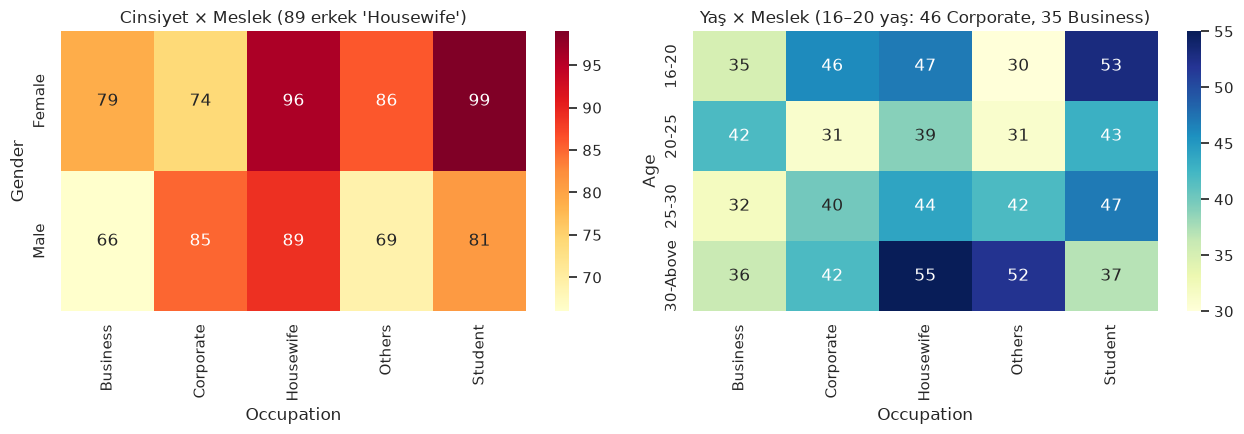

In [4]:
plaus_df = check_plausibility(df)
display(plaus_df)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
ct_go = pd.crosstab(df["Gender"], df["Occupation"])
sns.heatmap(ct_go, annot=True, fmt="d", cmap="YlOrRd", ax=axes[0])
axes[0].set_title("Cinsiyet × Meslek (89 erkek 'Housewife')")
ct_ao = pd.crosstab(df["Age"], df["Occupation"])
sns.heatmap(ct_ao, annot=True, fmt="d", cmap="YlGnBu", ax=axes[1])
axes[1].set_title("Yaş × Meslek (16–20 yaş: 46 Corporate, 35 Business)")
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "04_mantiksal_tutarlilik.png"), dpi=150)
plt.show()

### 2.3 Tek değişkenli dağılımlar ve tekdüzelik (uniformity) testi
Gerçek anket verilerinde yanıtlar belirgin biçimde dengesizdir (ör. TÜİK verisinde %72,7 belirti yok).
Her sütun için *"tüm kategoriler eşit olasılıklı"* sıfır hipotezi ki-kare uyum iyiliği testiyle sınanır.

,column,label_tr,n_categories,top_category,top_share,chi2,p_value,indistinguishable_from_uniform
0,Age,Yaş,4,30-Above,0.2694,3.311,0.3462,True
1,Gender,Cinsiyet,2,Female,0.5267,2.350,0.1253,True
2,Occupation,Meslek,5,Housewife,0.2245,7.044,0.1336,True
3,Days_Indoors,Evde Kalınan Gün,5,31-60 days,0.2075,1.182,0.8810,True
4,Growing_Stress,Artan Stres,3,Yes,0.3653,4.007,0.1348,True
5,Quarantine_Frustrations,Karantina Hayal Kırıklığı,3,Yes,0.3689,4.961,0.0837,True
6,Changes_Habits,Alışkanlık Değişimi,3,Yes,0.3701,5.551,0.0623,True
7,Mental_Health_History,Aile Ruh Sağlığı Öyküsü,3,No,0.3447,1.524,0.4667,True
8,Weight_Change,Kilo Değişimi,3,Maybe,0.3410,0.308,0.8572,True
9,Mood_Swings,Ruh Hâli Değişimleri,3,Medium,0.3398,0.417,0.8116,True


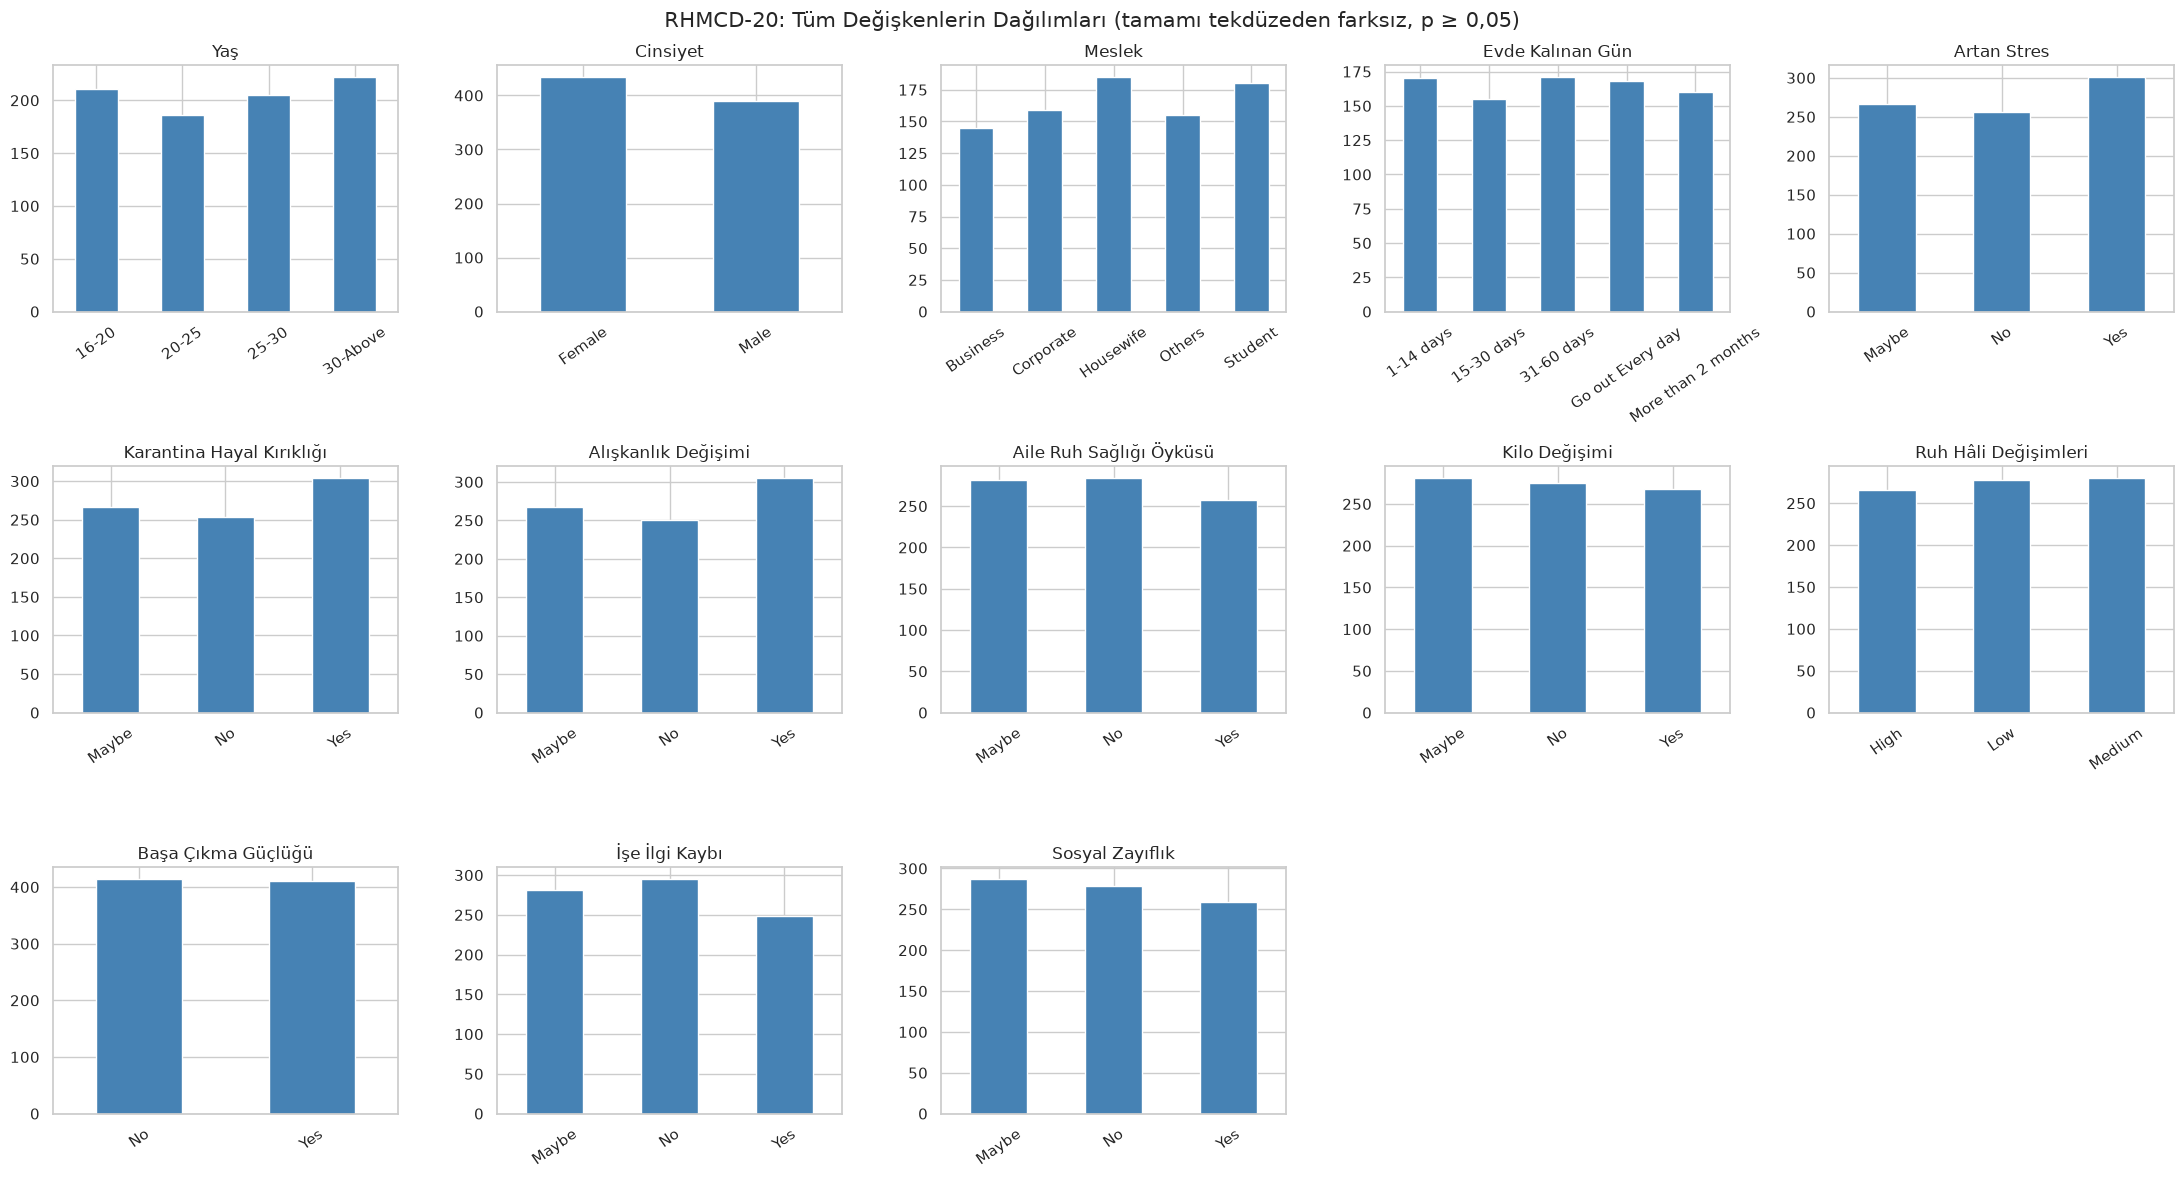

In [5]:
unif_df = check_uniformity(df)
display(unif_df)

fig, axes = plt.subplots(3, 5, figsize=(22, 12))
for ax, c in zip(axes.flat, df.columns):
    df[c].value_counts().sort_index().plot.bar(ax=ax, color="steelblue")
    ax.set_title(TR_LABELS[c]); ax.set_xlabel(""); ax.tick_params(axis="x", rotation=35)
for ax in axes.flat[len(df.columns):]:
    ax.axis("off")
plt.suptitle("RHMCD-20: Tüm Değişkenlerin Dağılımları (tamamı tekdüzeden farksız, p ≥ 0,05)", fontsize=15)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "01_dagilimlar.png"), dpi=150)
plt.show()

## 3. Değişkenler arası ilişki: Cramér's V (yanlılık düzeltmeli) ve BH-FDR

Orijinal çalışmada sütunlar `LabelEncoder` ile alfabetik tamsayıya çevrilip **Pearson korelasyonu** hesaplanmıştı.
Kategorik değişkenler için doğru ölçü **Bergsma (2013) yanlılık düzeltmeli Cramér's V** ve çoklu karşılaştırma için
**Benjamini–Hochberg FDR** düzeltmesidir.

78 çift test edildi | ham p<0.05: 2 | FDR q<0.05: 0 | max V = 0.068


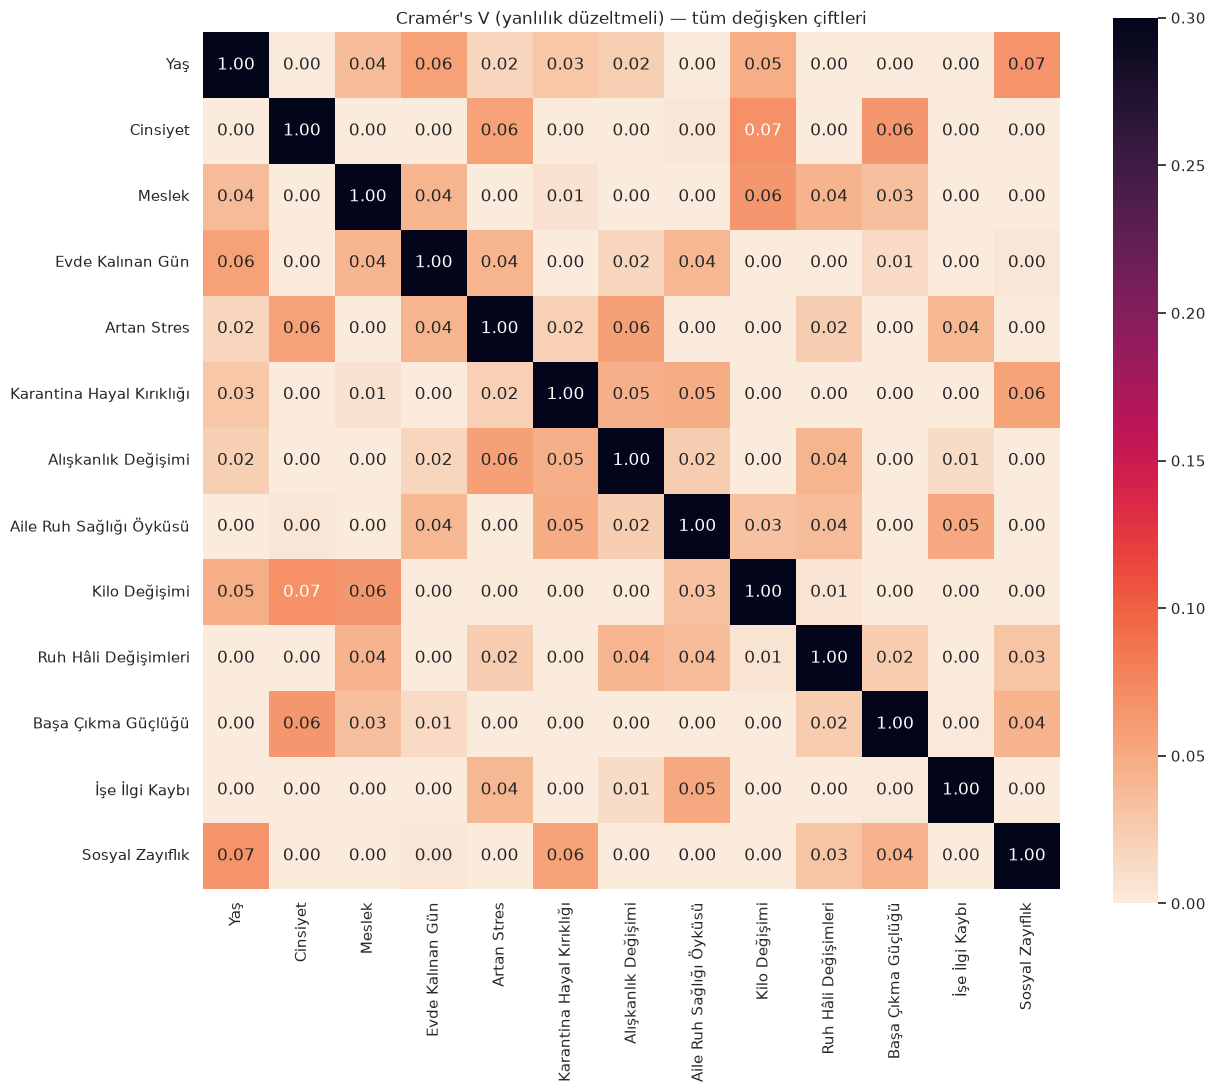

,var_a_tr,var_b_tr,cramers_v,p_value,q_fdr
0,Cinsiyet,Başa Çıkma Güçlüğü,0.0644,0.0357,0.7489
1,Yaş,Sosyal Zayıflık,0.0667,0.0383,0.7489
2,Artan Stres,Alışkanlık Değişimi,0.0577,0.0500,0.7489
3,Cinsiyet,Kilo Değişimi,0.0681,0.0544,0.7489
4,Karantina Hayal Kırıklığı,Sosyal Zayıflık,0.0557,0.0586,0.7489
5,Yaş,Evde Kalınan Gün,0.0574,0.0648,0.7489
6,Meslek,Kilo Değişimi,0.0634,0.0672,0.7489
7,Aile Ruh Sağlığı Öyküsü,İşe İlgi Kaybı,0.0514,0.0799,0.7670
8,Cinsiyet,Artan Stres,0.0574,0.0946,0.7670
9,Karantina Hayal Kırıklığı,Aile Ruh Sağlığı Öyküsü,0.0482,0.0983,0.7670


In [6]:
V_mat, pairs = pairwise_cramers_v(df)
V_tr = V_mat.rename(index=TR_LABELS, columns=TR_LABELS)
print(
    f"{len(pairs)} çift test edildi | ham p<0.05: {int((pairs['p_value'] < 0.05).sum())} "
    f"| FDR q<0.05: {int((pairs['q_fdr'] < 0.05).sum())} | max V = {pairs['cramers_v'].max():.3f}"
)

plt.figure(figsize=(13, 11))
sns.heatmap(V_tr, annot=True, fmt=".2f", cmap="rocket_r", vmin=0, vmax=0.3, square=True)
plt.title("Cramér's V (yanlılık düzeltmeli) — tüm değişken çiftleri")
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "02_cramers_v.png"), dpi=150)
plt.show()
pairs[["var_a_tr", "var_b_tr", "cramers_v", "p_value", "q_fdr"]].head(10).round(4)

## 4. Literatür temelli hipotez testleri

Literatürde tutarlı biçimde kanıtlanmış 6 temel ilişki (Salk vd., 2017; Brooks vd., 2020; Hosen vd., 2021; Yıldız vd., 2024) RHMCD-20 üzerinde sınanır.

In [7]:
hyps = run_literature_hypotheses(df)
hyps[["id", "var_a", "var_b", "cramers_v", "p_value", "q_fdr", "supported_fdr_05", "rationale"]]

,id,var_a,var_b,cramers_v,p_value,q_fdr,supported_fdr_05,rationale
0,H1,Gender,Growing_Stress,0.0574,0.0946,0.4050,False,Kadınlarda stres/depresif belirti daha yüksekt...
1,H2,Days_Indoors,Growing_Stress,0.0425,0.2025,0.4050,False,Uzun karantina süresi stresle ilişkilidir (Bro...
2,H3,Mental_Health_History,Mood_Swings,0.0372,0.1790,0.4050,False,Aile ruh sağlığı öyküsü duygudurum dalgalanmal...
3,H4,Changes_Habits,Weight_Change,0.0000,0.5320,0.6384,False,Yeme/uyku alışkanlığı değişimi kilo değişimiyl...
4,H5,Growing_Stress,Coping_Struggles,0.0000,0.9929,0.9929,False,Artan stres başa çıkma güçlüğüyle ilişkilidir
5,H6,Occupation,Gender,0.0000,0.4754,0.6384,False,Meslek dağılımı cinsiyete göre farklılaşır (ör...


## 5. Modelleme — sızıntısız, çapraz doğrulamalı, taban çizgili

Tasarım ilkeleri (Kapoor & Narayanan, 2023; TRIPOD+AI, Collins vd., 2024):
* Tüm ön işleme adımları bir `Pipeline` içinde, yalnızca eğitim katlarında öğrenilir.
* **Tekrarlı tabakalı 5-katlı çapraz doğrulama** (5×3).
* **Taban çizgileri:** `DummyClassifier` (en sık sınıf ve tabakalı rastgele).
* **Metrikler:** doğruluk, *dengeli doğruluk*, makro-F1, ROC-AUC (OvR).
* **Permütasyon testi:** etiketler 200 kez karıştırılarak modelin şanstan iyi olup olmadığı sınanır.

### 5.1 Ana hedef: `Sosyal Zayıflık` (3 sınıf) — orijinal çalışmadaki hedef

Sınıflar: {'Maybe': 287, 'No': 278, 'Yes': 259}
Permütasyon testi (LogReg, dengeli doğruluk): gözlenen=0.322 | şans ort.=0.333 | p=0.731


,model,accuracy_mean,accuracy_std,balanced_accuracy_mean,balanced_accuracy_std,f1_macro_mean,f1_macro_std,roc_auc_mean,roc_auc_std
0,Dummy (most_frequent),0.3483,0.0027,0.3333,0.0000,0.1722,0.0010,0.5000,0.0000
1,Dummy (stratified),0.3616,0.0445,0.3607,0.0445,0.3607,0.0448,0.5205,0.0334
2,LogisticRegression (L2),0.3293,0.0339,0.3274,0.0337,0.3255,0.0327,0.4943,0.0289
3,CategoricalNB,0.3204,0.0359,0.3189,0.0357,0.3173,0.0347,0.4914,0.0302
4,RandomForest,0.3337,0.0305,0.3309,0.0304,0.3284,0.0310,0.5099,0.0243
5,HistGradientBoosting,0.3350,0.0271,0.3336,0.0269,0.3325,0.0269,0.5089,0.0248
6,kNN (k=15),0.3345,0.0330,0.3303,0.0327,0.3227,0.0324,0.5069,0.0253


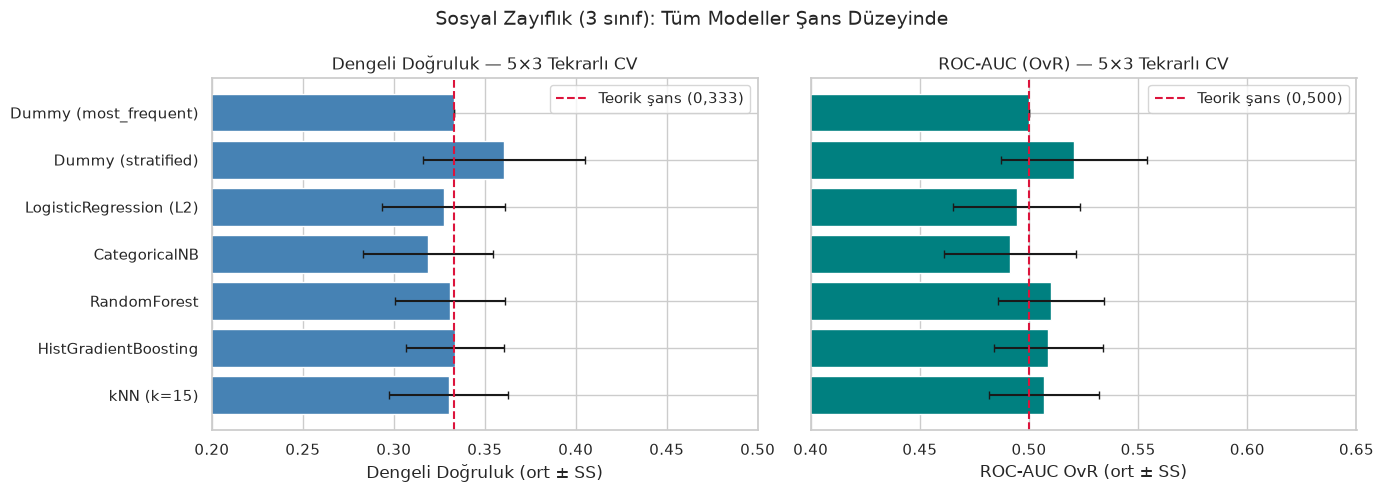

In [8]:
rep_sw = evaluate_target(df, target="Social_Weakness", n_splits=5, n_repeats=3, n_permutations=200, random_state=RANDOM_STATE)
print(f"Sınıflar: {rep_sw.class_counts}")
print(
    f"Permütasyon testi (LogReg, dengeli doğruluk): gözlenen={rep_sw.permutation_score:.3f} "
    f"| şans ort.={rep_sw.permutation_null_mean:.3f} | p={rep_sw.permutation_p_value:.3f}"
)
display(rep_sw.cv_summary)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
s = rep_sw.cv_summary
y_pos = np.arange(len(s))
axes[0].barh(y_pos, s["balanced_accuracy_mean"], xerr=s["balanced_accuracy_std"], color="steelblue", capsize=3)
axes[0].axvline(1 / 3, color="crimson", ls="--", label="Teorik şans (0,333)")
axes[0].set_yticks(y_pos); axes[0].set_yticklabels(s["model"]); axes[0].invert_yaxis()
axes[0].set_xlim(0.2, 0.5); axes[0].set_xlabel("Dengeli Doğruluk (ort ± SS)"); axes[0].legend()
axes[0].set_title("Dengeli Doğruluk — 5×3 Tekrarlı CV")

axes[1].barh(y_pos, s["roc_auc_mean"], xerr=s["roc_auc_std"], color="teal", capsize=3)
axes[1].axvline(0.5, color="crimson", ls="--", label="Teorik şans (0,500)")
axes[1].set_yticks(y_pos); axes[1].set_yticklabels([""] * len(s)); axes[1].invert_yaxis()
axes[1].set_xlim(0.4, 0.65); axes[1].set_xlabel("ROC-AUC OvR (ort ± SS)"); axes[1].legend()
axes[1].set_title("ROC-AUC (OvR) — 5×3 Tekrarlı CV")

plt.suptitle("Sosyal Zayıflık (3 sınıf): Tüm Modeller Şans Düzeyinde", fontsize=14)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "05_model_kiyaslama.png"), dpi=150)
plt.show()

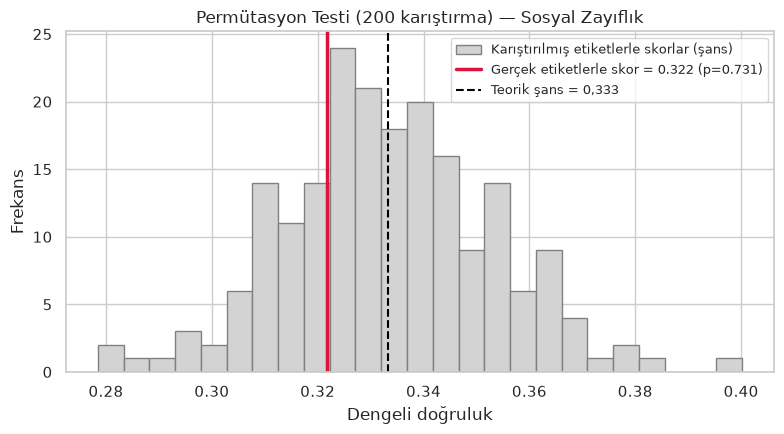

In [9]:
plt.figure(figsize=(8, 4.5))
plt.hist(rep_sw.permutation_scores, bins=25, color="lightgray", edgecolor="gray", label="Karıştırılmış etiketlerle skorlar (şans)")
plt.axvline(rep_sw.permutation_score, color="crimson", lw=2.5, label=f"Gerçek etiketlerle skor = {rep_sw.permutation_score:.3f} (p={rep_sw.permutation_p_value:.3f})")
plt.axvline(1 / 3, color="black", ls="--", label="Teorik şans = 0,333")
plt.xlabel("Dengeli doğruluk"); plt.ylabel("Frekans"); plt.legend(fontsize=9)
plt.title("Permütasyon Testi (200 karıştırma) — Sosyal Zayıflık")
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "03_permutasyon_testi.png"), dpi=150)
plt.show()

### 5.2 İkili formülasyon (`Sosyal Zayıflık = Evet`) ve alternatif hedefler (duyarlılık analizi)

In [10]:
rep_bin = evaluate_target(df, target="Social_Weakness", binary_positive="Yes", n_splits=5, n_repeats=3, n_permutations=100, random_state=RANDOM_STATE)
display(rep_bin.cv_summary)

ozet = []
for t in ["Growing_Stress", "Mood_Swings", "Coping_Struggles"]:
    r = evaluate_target(df, target=t, n_splits=5, n_repeats=3, n_permutations=100, random_state=RANDOM_STATE)
    tbl = r.cv_summary.set_index("model")
    ozet.append({
        "Hedef": TR_LABELS[t],
        "Taban Dengeli Doğr.": tbl.loc["Dummy (most_frequent)", "balanced_accuracy_mean"],
        "LogReg Dengeli Doğr.": tbl.loc["LogisticRegression (L2)", "balanced_accuracy_mean"],
        "HistGB Dengeli Doğr.": tbl.loc["HistGradientBoosting", "balanced_accuracy_mean"],
        "En Yüksek ROC-AUC": tbl["roc_auc_mean"].max(),
        "Permütasyon p": round(r.permutation_p_value, 3),
    })
pd.DataFrame(ozet)

,model,accuracy_mean,accuracy_std,balanced_accuracy_mean,balanced_accuracy_std,f1_macro_mean,f1_macro_std,roc_auc_mean,roc_auc_std
0,Dummy (most_frequent),0.6857,0.0017,0.5000,0.0000,0.4068,0.0006,0.5000,0.0000
1,Dummy (stratified),0.5769,0.0286,0.5019,0.0332,0.5017,0.0337,0.5019,0.0332
2,LogisticRegression (L2),0.6764,0.0108,0.4998,0.0112,0.4243,0.0213,0.5331,0.0355
3,CategoricalNB,0.6776,0.0135,0.5098,0.0136,0.4522,0.0213,0.5316,0.0355
4,RandomForest,0.6833,0.0037,0.4986,0.0036,0.4071,0.0054,0.5153,0.0427
5,HistGradientBoosting,0.6671,0.0169,0.4993,0.0136,0.4392,0.0171,0.5167,0.0327
6,kNN (k=15),0.6570,0.0138,0.4906,0.0108,0.4303,0.0148,0.4974,0.0423


,Hedef,Taban Dengeli Doğr.,LogReg Dengeli Doğr.,HistGB Dengeli Doğr.,En Yüksek ROC-AUC,Permütasyon p
0,Artan Stres,0.3333,0.3352,0.3473,0.5128,0.248
1,Ruh Hâli Değişimleri,0.3333,0.3407,0.3312,0.5062,0.515
2,Başa Çıkma Güçlüğü,0.5000,0.4988,0.4873,0.5084,0.327


## 6. Alt grup adalet (fairness) ve kalibrasyon (Brier) analizi (TRIPOD+AI)

Veriyi cinsiyete göre parçalayıp örneklem kaybetmek yerine tek bir model eğitilir ve demografik alt gruplardaki
(cinsiyet ve yaş) ayrım gücü (`ROC-AUC`) ile kalibrasyon (`Brier skoru`) birlikte raporlanır.

,group_col,subgroup,n,positive_rate,accuracy,balanced_accuracy,f1_macro,roc_auc,brier_score
0,Gender,Female,434,0.3157,0.6705,0.4958,0.4207,0.5440,0.2176
1,Gender,Male,390,0.3128,0.6821,0.5030,0.4277,0.5339,0.2161
2,Age,16-20,211,0.3033,0.6967,0.5044,0.4253,0.5305,0.2126
3,Age,20-25,186,0.3925,0.5753,0.4856,0.4166,0.5486,0.2403
4,Age,25-30,205,0.2585,0.7415,0.5000,0.4258,0.4970,0.1976
5,Age,30-Above,222,0.3108,0.6802,0.4935,0.4048,0.4946,0.2191


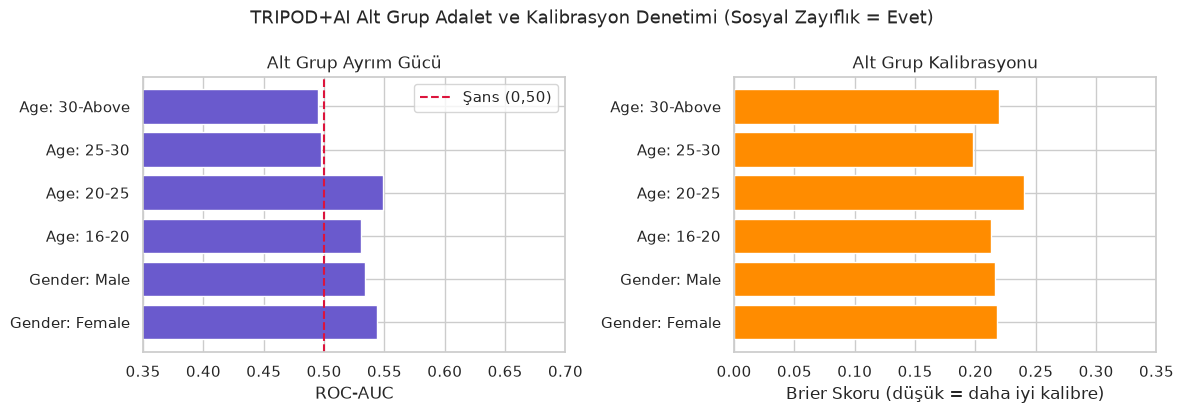

In [11]:
fair_gender = subgroup_fairness_report(df, target="Social_Weakness", positive_label="Yes", group_col="Gender")
fair_age = subgroup_fairness_report(df, target="Social_Weakness", positive_label="Yes", group_col="Age")
fair_all = pd.concat([fair_gender, fair_age], ignore_index=True)
display(fair_all)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
labels = [f"{r.group_col}: {r.subgroup}" for _, r in fair_all.iterrows()]
axes[0].barh(labels, fair_all["roc_auc"], color="slateblue")
axes[0].axvline(0.5, color="crimson", ls="--", label="Şans (0,50)")
axes[0].set_xlim(0.35, 0.70); axes[0].set_xlabel("ROC-AUC"); axes[0].set_title("Alt Grup Ayrım Gücü"); axes[0].legend()

axes[1].barh(labels, fair_all["brier_score"], color="darkorange")
axes[1].set_xlim(0.0, 0.35); axes[1].set_xlabel("Brier Skoru (düşük = daha iyi kalibre)"); axes[1].set_title("Alt Grup Kalibrasyonu")
plt.suptitle("TRIPOD+AI Alt Grup Adalet ve Kalibrasyon Denetimi (Sosyal Zayıflık = Evet)", fontsize=13)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "06_altgrup_adalet.png"), dpi=150)
plt.show()

## 7. Orijinal not defterinin yeniden üretimi ve H1 hatası

Orijinal `analiz.ipynb` hücre 21–23'te `X_train_resampled` önce erkek, sonra kadın verisiyle **üzerine yazılmakta**;
bu nedenle *"Erkek"* modelleri aslında **kadın eğitim verisiyle** eğitilip erkek test verisinde ölçülmektedir.

In [12]:
reproduce_original_bug(df_tr, random_state=RANDOM_STATE)

,model,male_acc_buggy_trained_on_female,male_acc_fixed,female_acc
0,LogisticRegression,0.3419,0.2991,0.3511
1,RandomForest,0.3761,0.2735,0.3206
2,SVC,0.3675,0.2479,0.3740
3,kNN,0.4444,0.3248,0.3206
4,GradientBoosting,0.3846,0.2821,0.3435


## 8. Faz 1–2 Altyapı Gösterimi: PHQ-9 / GAD-7 Tarama ve Türkçe Psikolinguistik Özellikler

Literatüre dayalı yeni [`mental_pulse.screening`](../src/mental_pulse/screening.py) modülü, bir sonraki fazda
(etik onaylı Türkçe veri toplama ve NLP modeli) kullanılacak **geçerlenmiş ölçek puanlaması (PHQ-9/GAD-7 + Madde 9 kriz bayrağı)**
ve **açıklanabilir Türkçe dilsel belirteç çıkarımını** (Rude vd., 2004; Al-Mosaiwi & Johnstone, 2018; Eichstaedt vd., 2018) sağlar.

In [13]:
ornek_phq9 = score_phq9([2, 2, 1, 2, 1, 1, 1, 0, 1])
ornek_gad7 = score_gad7([2, 2, 1, 2, 1, 1, 1])
print("PHQ-9 örnek:", ornek_phq9.total_score, "|", ornek_phq9.severity_tr, "| Kriz bayrağı:", ornek_phq9.crisis_flag)
print("GAD-7 örnek:", ornek_gad7.total_score, "|", ornek_gad7.severity_tr, "| Pozitif tarama:", ornek_gad7.positive_screen)

ornek_metinler = {
    "Yüksek depresif/mutlakiyetçi dil": "Ben her zaman kendimi çok yalnız ve umutsuz hissediyorum. Hiçbir şey asla düzelmeyecek, tamamen tükendim ve geceleri uyuyamıyorum.",
    "Olumlu/dengeli dil": "Bugün yürüyüş yaptık, çok güzel ve huzurlu bir gündü. Arkadaşlarla keyifli sohbet ettik, oldukça enerjik ve mutluyuz.",
}
pd.DataFrame({k: extract_turkish_linguistic_features(v).to_dict() for k, v in ornek_metinler.items()}).T

PHQ-9 örnek: 11 | Orta düzey depresif belirti | Kriz bayrağı: True
GAD-7 örnek: 10 | Orta düzey anksiyete | Pozitif tarama: True


,word_count,sentence_count,avg_word_length,first_person_singular_ratio,absolutist_ratio,negative_emotion_ratio,positive_emotion_ratio,somatic_sleep_ratio,affect_balance,question_mark_count,exclamation_mark_count
Yüksek depresif/mutlakiyetçi dil,18.0,2.0,6.111,0.1111,0.2222,0.1667,0.0000,0.0556,-0.1667,0.0,0.0
Olumlu/dengeli dil,17.0,2.0,5.706,0.0000,0.0000,0.0000,0.2941,0.0000,0.2941,0.0,0.0


## 9. Sonuç

1. **Hiçbir model şans düzeyini anlamlı biçimde aşamamaktadır.** Dengeli doğruluk ≈ 0,33 (3 sınıf için şans), ROC-AUC ≈ 0,50 ve permütasyon testi anlamsızdır.
2. Kök neden algoritma değil, **RHMCD-20 verisinde öğrenilebilir sinyal bulunmamasıdır** (tüm çiftlerde Cramér's V < 0,07; FDR sonrası 0 anlamlı çift; 13/13 tekdüze sütun; 89 erkek "Housewife").
3. Orijinal çalışmadaki %34–44 doğruluk değerleri, hem H1 eğitim verisi üzerine yazma hatası hem de taban çizgisi eksikliği nedeniyle yanıltıcıdır.
4. Projenin hedefi olan *depresyonun erken tespiti* için geçerlenmiş ölçeklerle (PHQ-9/PHQ-8, GAD-7) etiketlenmiş verilere ve dijital etkileşim verisine (Türkçe NLP + pasif hareketlilik) geçilmesi gerekir. Ayrıntılı yol haritası: [`docs/ARASTIRMA_RAPORU.md`](../docs/ARASTIRMA_RAPORU.md).